# Images 01 · Specular microscopy image validation

**Objective:** verify that each tissue has one valid specular microscopy image, that the files are intact and uniform (size, mode, format), and that each image carries the same grade as its tissue record.

**Derived from:** `notebooks/images/01_image_dataset_validation.ipynb`, the image checks in `notebooks/images/02_image_baseline.ipynb`, and `scripts/audit_sp_images.py` / `scripts/prepare_image_dataset.py` (which built the clean manifest).
**Runtime:** about 30 seconds (reads and hashes every image).

Set up paths and load the clean image manifest (one row per tissue ID with an image).

In [1]:
import hashlib
import sys
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import cleaned_setup as cs
import modeling_setup as ms

manifest = pd.read_csv(cs.MANIFEST_PATH)
manifest["Path"] = manifest["Selected_Image"].map(lambda p: cs.IMAGE_DIR / Path(p).name)
print("Manifest rows:", len(manifest), "| unique tissue IDs:", manifest["Normalized_ID"].nunique())
manifest["Tissue_Grade_Clean"].value_counts(dropna=False).rename("Images").to_frame()

Manifest rows: 1024 | unique tissue IDs: 1024


,Images
Tissue_Grade_Clean,
A+,530
A,314
B,165
NaN,15


## 1. Duplicate source files

Some tissues had several source files. Byte-identical copies were collapsed; IDs whose copies contain **different** images were flagged for manual review instead of choosing one arbitrarily.

In [2]:
review = pd.read_csv(cs.IMAGE_DATA_DIR / "duplicate_review.csv")
print("Source files per tissue:", manifest["Source_File_Count"].value_counts().sort_index().to_dict())
print(review["Status"].str.split(":").str[0].value_counts().to_string())
flagged = review.loc[review["Status"].str.contains("manual review", na=False), "Tissue_ID"].tolist()
print("Flagged for manual review (left out of the clean manifest by prepare_image_dataset.py):", flagged)
assert sorted(flagged) == sorted(cs.REVIEW_IDS)
print("Flagged IDs in the manifest:", int(manifest["Tissue_ID"].isin(flagged).sum()))

Source files per tissue: {1: 532, 2: 492}
Status
Byte-identical copy                                 492
Different image contents; manual review required      2
Flagged for manual review (left out of the clean manifest by prepare_image_dataset.py): ['NEB-2024-08-16259 R', 'NEB-2025-09-17471 R']
Flagged IDs in the manifest: 0


## 2. File integrity and format

Every file must exist and still match the SHA-256 recorded when the manifest was built.

In [3]:
exists = manifest["Path"].map(Path.is_file)
hash_ok = manifest.loc[exists, "Path"].map(lambda p: hashlib.sha256(p.read_bytes()).hexdigest()) == manifest.loc[exists, "SHA256"]
print(f"Files present: {exists.sum()}/{len(manifest)} | SHA-256 unchanged: {hash_ok.sum()}/{exists.sum()}")
assert exists.all() and hash_ok.all()

Files present: 1024/1024 | SHA-256 unchanged: 1024/1024


Read each image header: all images share one size, mode and format (the application flags any other size for review).

In [4]:
headers = []
for path in manifest["Path"]:
    with Image.open(path) as img:
        headers.append({"Size (w × h)": f"{img.size[0]} × {img.size[1]}", "Mode": img.mode, "Format": img.format})
pd.DataFrame(headers).value_counts().rename("Images").to_frame()

,,,Images
Size (w × h),Mode,Format,
1296 × 972,L,JPEG,1024


Basic intensity checks on every image: no blank or constant images (image quality and cell visibility were not otherwise assessed).

In [5]:
stats = []
for path in manifest["Path"]:
    with Image.open(path) as img:
        pixels = np.asarray(img, dtype=np.float32)
    stats.append((pixels.min(), pixels.max(), pixels.mean(), pixels.std()))
stats = pd.DataFrame(stats, columns=["min", "max", "mean", "std"])
print(f"Intensity range 0–255 | mean brightness {stats['mean'].mean():.1f} (range {stats['mean'].min():.1f}–{stats['mean'].max():.1f}) "
      f"| mean contrast (SD) {stats['std'].mean():.1f} | constant images: {(stats['std'] == 0).sum()}")

Intensity range 0–255 | mean brightness 82.0 (range 33.8–255.0) | mean contrast (SD) 42.4 | constant images: 1


One image is constant (every pixel 255: a blank white frame). Check which cohorts its tissue belongs to (no ID printed).

In [6]:
blank = manifest.loc[(stats["std"] == 0).to_numpy()]
k2_ids = set(cs.image_cohort()[0]["Tissue_ID"])
k3, _, has_ecd = cs.primary_cohort()
for _, row in blank.iterrows():
    in_k3 = row["Tissue_ID"] in set(k3["Tissue_ID"])
    print(f"Grade {row['Tissue_Grade_Clean']} | in K2: {row['Tissue_ID'] in k2_ids} | in K3 (primary cohort, deployed model's training data): {in_k3} "
          f"| in K4 (evaluation set): {in_k3 and bool(has_ecd[(k3['Tissue_ID'] == row['Tissue_ID']).to_numpy()][0])} "
          f"| Konan values recorded: {k3.loc[k3['Tissue_ID'] == row['Tissue_ID'], ms.NUMERIC_FEATURES].notna().any(axis=1).any() if in_k3 else 'n/a'}")

Grade A | in K2: True | in K3 (primary cohort, deployed model's training data): True | in K4 (evaluation set): False | Konan values recorded: False


## 3. Image–label alignment

Match images to the cleaned tissue records by normalised `Tissue_ID`; the grade stored with each image must equal the record's grade.

In [7]:
records = pd.read_excel(ms.DATA_PATH)
records["Normalized_ID"] = records["Tissue_ID"].map(cs.normalize_id)
manifest["Match"] = manifest["Tissue_ID"].map(cs.normalize_id)
merged = manifest.merge(records[["Normalized_ID", ms.TARGET]], left_on="Match", right_on="Normalized_ID",
                        how="left", suffixes=("_image", "_record"), validate="one_to_one", indicator=True)
agree = merged[f"{ms.TARGET}_image"].fillna("missing") == merged[f"{ms.TARGET}_record"].fillna("missing")
print(f"Images matched to a tissue record: {(merged['_merge'] == 'both').sum()}/{len(manifest)} | grade agreement: {agree.sum()}/{len(merged)}")
print(f"Tissue records without an image: {len(set(records['Normalized_ID']) - set(manifest['Match']))}")
assert (merged["_merge"] == "both").all() and agree.all()

Images matched to a tissue record: 1024/1024 | grade agreement: 1024/1024
Tissue records without an image: 30


The modelling image cohort (K2): the labelled images in the manifest. (`cs.image_cohort()` also drops the two flagged IDs, a redundant safeguard because they are not in the manifest.)

In [8]:
k2, _ = cs.image_cohort()
print(f"K2: {len(k2)} tissues ({len(manifest)} images − {manifest['Tissue_Grade_Clean'].isna().sum()} unlabelled)")
k2[ms.TARGET].value_counts().reindex(cs.CLASSES).rename("Tissues").to_frame().T

K2: 1009 tissues (1024 images − 15 unlabelled)


Tissue_Grade_Clean,A+,A,B
Tissues,530,314,165


## 4. What the images look like

Four randomly chosen K2 images per grade (full field of view, downscaled for display). Differences between grades are not obvious to the eye, which foreshadows the weak image-only results.

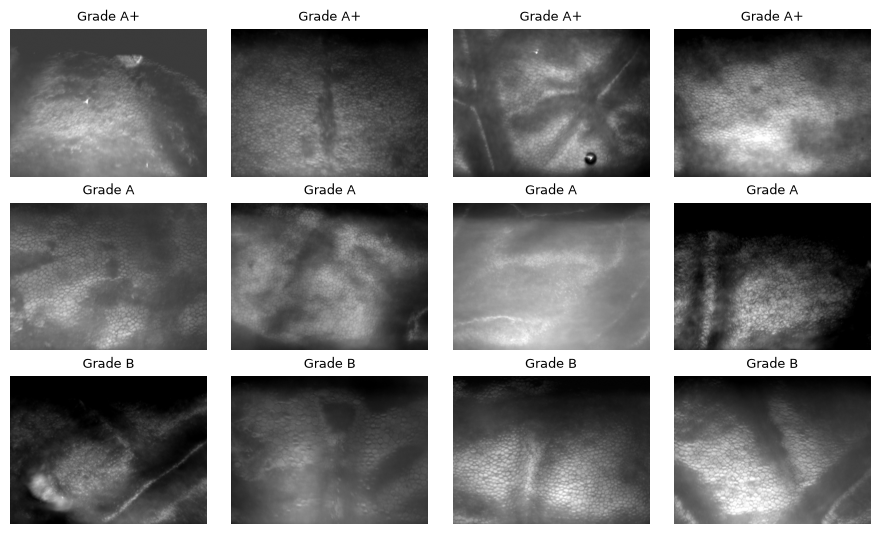

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(9, 5.4))
for row, grade in enumerate(cs.CLASSES):
    sample = k2[k2[ms.TARGET] == grade].sample(4, random_state=cs.SEED)
    for ax, path in zip(axes[row], sample["Selected_Image"]):
        with Image.open(cs.IMAGE_DIR / Path(path).name) as img:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Grade {grade}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusion

- 1,024 tissue IDs have an image; all files are present, unchanged since the audit, and 1296 × 972 8-bit greyscale JPEGs.
- **One image is blank (constant white).** Its tissue (grade A, no Konan values) is in K2 and K3, so it was in the training folds and in the deployed model's training data, but not in the K4 evaluation set. Found during this cleanup and not corrected, so that results stay reproducible; the application's domain validator is designed to reject content-free images.
- Every image matches a tissue record with the same grade. The 2 IDs whose duplicate files differ were already left out of the manifest; removing the 15 unlabelled images leaves the image cohort K2 with 1,009 tissues (A+ 530, A 314, B 165).

**Limitations:** image quality and cell visibility were not assessed beyond these checks. All images come from one eye bank's microscope.